# 02  -  Customer Value, Retention and Instalments  *(primary business cases B + D)*

> **Management questions**
> - **B.** Who are our valuable customers, and why do so few come back?
> - **D.** Does offering instalments increase basket size?

The two are one story: B shows the business barely retains anyone, D shows how customers
pay, and section 4 asks whether the way a customer pays for their **first** order says
anything about whether they come back.

Everything reads from the **marts** layer (`agg_customer_clv`, `agg_customer_cohort`,
`agg_installment_basket`, `agg_customer_rfm`, `agg_monthly_sales`, `fct_orders`). Customers are counted as **people**
(`customer_unique_id`), canceled and unavailable orders are excluded, and revenue is item
price with freight excluded, exactly as documented in `dbt/olist/models/marts/_olist__marts.yml`.

Structure:

1. **WHO is valuable**  -  lifetime value, how concentrated it is, and RFM segments
2. **WHY so few come back**  -  retention curve, cohorts, time to second purchase, spend over time
3. **INSTALMENTS and basket size**  -  order value by instalment count and payment type, and over time
4. **B + D**  -  does the first payment predict the customer, after controlling for price?
5. **Reconciliation**  -  this notebook's numbers are the tested numbers


In [1]:
# warehouse.py lives at the repository root so the notebooks and the Streamlit
# dashboard share one definition of which datasets to read. Walk up from the
# working directory to find it, so the notebook runs the same whether it is
# opened in Jupyter or executed headless by `make analyse`.
import sys, pathlib
_root = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
             if (p / "warehouse.py").exists())
sys.path.insert(0, str(_root))

import pandas as pd
import matplotlib.pyplot as plt

from warehouse import q, marts, staging, raw, style_charts, describe_connection, SNAPSHOT_DATE

style_charts()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

print(describe_connection())

project=olist-group2-i4gq1  location=US  target=dev
marts dataset=dbt_bd_marts
analytical snapshot date=2018-10-17


In [2]:
# Headline numbers first, so every chart below has a baseline to be read against.
headline = q(f"""
    select
        count(*)                                                    as customers,
        countif(is_repeat_customer)                                 as repeat_customers,
        round(avg(if(is_repeat_customer, 1, 0)), 4)                 as repeat_rate,
        round(avg(lifetime_revenue), 2)                             as avg_clv,
        round(approx_quantiles(lifetime_revenue, 100)[offset(50)], 2) as median_clv,
        round(sum(lifetime_revenue), 2)                             as revenue,
        round(safe_divide(sum(repeat_revenue), sum(lifetime_revenue)), 4) as repeat_revenue_share
    from {marts('agg_customer_clv')}
""")
h = headline.iloc[0]
print(f"Customers (people)          : {h.customers:,.0f}")
print(f"Bought more than once       : {h.repeat_customers:,.0f}  ({h.repeat_rate:.2%})")
print(f"Average lifetime value      : R$ {h.avg_clv:,.2f}")
print(f"Median lifetime value       : R$ {h.median_clv:,.2f}")
print(f"Total revenue               : R$ {h.revenue:,.2f}")
print(f"Revenue from repeat orders  : {h.repeat_revenue_share:.2%}")


Customers (people)          : 94,990
Bought more than once       : 2,888  (3.04%)
Average lifetime value      : R$ 142.07
Median lifetime value       : R$ 89.90
Total revenue               : R$ 13,494,400.74
Revenue from repeat orders  : 2.93%


## 1. WHO are our valuable customers?

### 1a. How concentrated is value?

**Definition.** Lifetime value (CLV) is **realised** spend: the sum of item price over a
person's kept orders. It is not a forecast. With ~97% of customers buying once, a
predictive model would be fitted on almost no repeat behaviour, so we report what was
actually spent and rank it.


,clv_decile,customers,from_rs,avg_clv,revenue,repeat_rate,avg_orders,revenue_share,cumulative_share
0,10,9499,282.0,584.0,5551026.0,0.0869,1.109,0.4114,0.4114
1,9,9499,180.0,221.0,2096580.0,0.0667,1.072,0.1554,0.5668
2,8,9499,139.0,157.0,1492109.0,0.0435,1.046,0.1106,0.6774
3,7,9499,110.0,123.0,1168889.0,0.0338,1.036,0.0866,0.7640
4,6,9499,90.0,99.0,938008.0,0.0221,1.023,0.0695,0.8335
5,5,9499,70.0,78.0,744174.0,0.0206,1.021,0.0551,0.8886
6,4,9499,53.0,61.0,575230.0,0.0140,1.015,0.0426,0.9312
7,3,9499,40.0,47.0,442039.0,0.0094,1.010,0.0328,0.9640
8,2,9499,26.0,33.0,309359.0,0.0051,1.005,0.0229,0.9869
9,1,9499,1.0,19.0,176987.0,0.0020,1.002,0.0131,1.0000


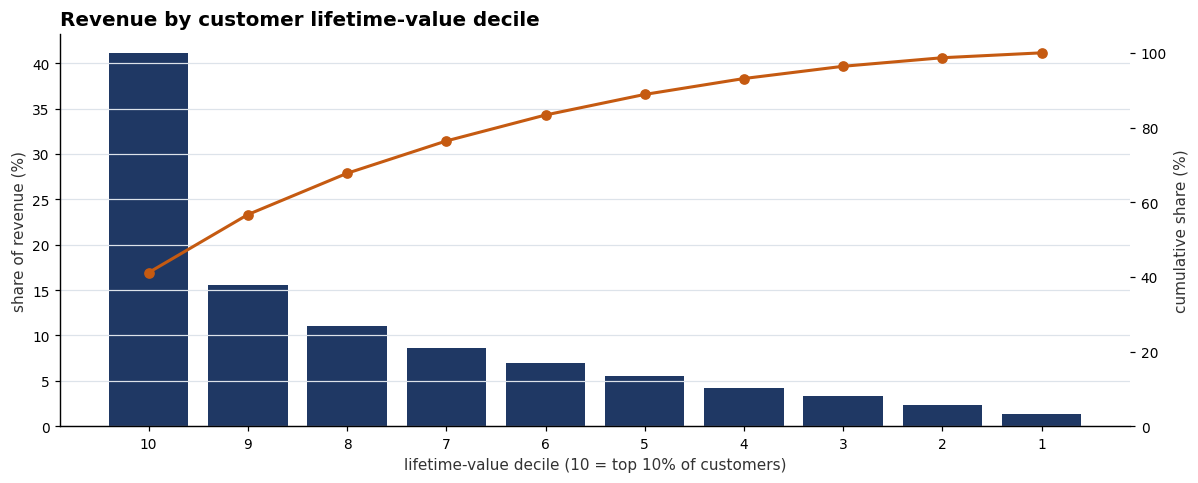

Top 10% of customers (spent R$ 282+) : 41.1% of revenue
Top 20% of customers                       : 56.7% of revenue


In [3]:
deciles = q(f"""
    select
        clv_decile,
        count(*)                                   as customers,
        round(min(lifetime_revenue), 0)            as from_rs,
        round(avg(lifetime_revenue), 0)            as avg_clv,
        round(sum(lifetime_revenue), 0)            as revenue,
        round(avg(if(is_repeat_customer, 1, 0)), 4) as repeat_rate,
        round(avg(lifetime_orders), 3)             as avg_orders
    from {marts('agg_customer_clv')}
    group by clv_decile
    order by clv_decile desc
""")
deciles["revenue_share"] = (deciles.revenue / deciles.revenue.sum()).round(4)
deciles["cumulative_share"] = deciles.revenue_share.cumsum().round(4)
display(deciles)

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(deciles.clv_decile.astype(str), deciles.revenue_share * 100, color="#1f3864")
ax2 = ax.twinx()
ax2.plot(deciles.clv_decile.astype(str), deciles.cumulative_share * 100,
         color="#c55a11", marker="o", linewidth=2)
ax.set_xlabel("lifetime-value decile (10 = top 10% of customers)")
ax.set_ylabel("share of revenue (%)"); ax2.set_ylabel("cumulative share (%)")
ax2.set_ylim(0, 105); ax2.grid(False)
ax.set_title("Revenue by customer lifetime-value decile")
plt.tight_layout(); plt.show()

top10 = deciles.loc[deciles.clv_decile == 10].iloc[0]
top20 = deciles.loc[deciles.clv_decile >= 9, "revenue_share"].sum()
print(f"Top 10% of customers (spent R$ {top10.from_rs:,.0f}+) : {top10.revenue_share:.1%} of revenue")
print(f"Top 20% of customers                       : {top20:.1%} of revenue")


### 1b. What does a valuable customer look like?

Comparing the top decile with everyone else on the attributes we actually hold: how
many orders, how they paid the first time, and where they live.


In [4]:
profile = q(f"""
    select
        if(c.clv_decile = 10, 'top 10%', 'other 90%')                as tier,
        count(*)                                                     as customers,
        round(avg(c.lifetime_orders), 3)                             as avg_orders,
        round(avg(if(c.is_repeat_customer, 1, 0)), 4)                as repeat_rate,
        round(avg(c.first_order_revenue), 0)                         as avg_first_order,
        round(avg(if(c.first_payment_type = 'credit_card', 1, 0)), 4) as paid_by_card,
        round(avg(if(c.first_order_installments > 1, 1, 0)), 4)      as first_order_in_instalments,
        round(avg(if(d.customer_region = 'Sudeste', 1, 0)), 4)       as lives_in_southeast
    from {marts('agg_customer_clv')} c
    left join {marts('dim_customer')} d using (customer_key)
    group by tier
    order by tier desc
""")
display(profile.set_index("tier").T)


tier,top 10%,other 90%
customers,9499.0000,85491.0000
avg_orders,1.1090,1.0260
repeat_rate,0.0869,0.0241
avg_first_order,559.0000,91.0000
paid_by_card,0.8186,0.7475
first_order_in_instalments,0.7396,0.4889
lives_in_southeast,0.6202,0.6921


### 1c. RFM segmentation: which customers need which action?

**Definition.** `agg_customer_rfm` scores every person 1-5 on **R**ecency (days since last
kept order, measured against the snapshot date, not today), **F**requency (kept orders)
and **M**onetary value (item revenue). Segment names are chosen so each implies a
different action. Because ~97% of people buy once, frequency thresholds are deliberately
low, otherwise "Champions" would be empty.

,rfm_segment,customers,revenue,avg_monetary,avg_frequency,avg_recency_days,repeat_rate,avg_review,high_value_late,share_of_customers,share_of_revenue
0,1. Champions,15680,4257902.0,272.0,1.073,141.0,0.0612,4.12,1078,0.1651,0.3155
1,"2. High value, recent",7579,1927369.0,254.0,1.072,269.0,0.0650,3.86,888,0.0798,0.1428
2,"3. At risk, high value",14737,4123332.0,280.0,1.055,444.0,0.0503,4.08,902,0.1551,0.3056
3,4. New / promising,14827,587483.0,40.0,1.000,138.0,0.0000,4.22,0,0.1561,0.0435
4,"5. Dormant, low value",15653,627360.0,40.0,1.008,446.0,0.0077,4.17,0,0.1648,0.0465
5,6. Occasional,26514,1970953.0,74.0,1.022,282.0,0.0216,4.11,0,0.2791,0.1461


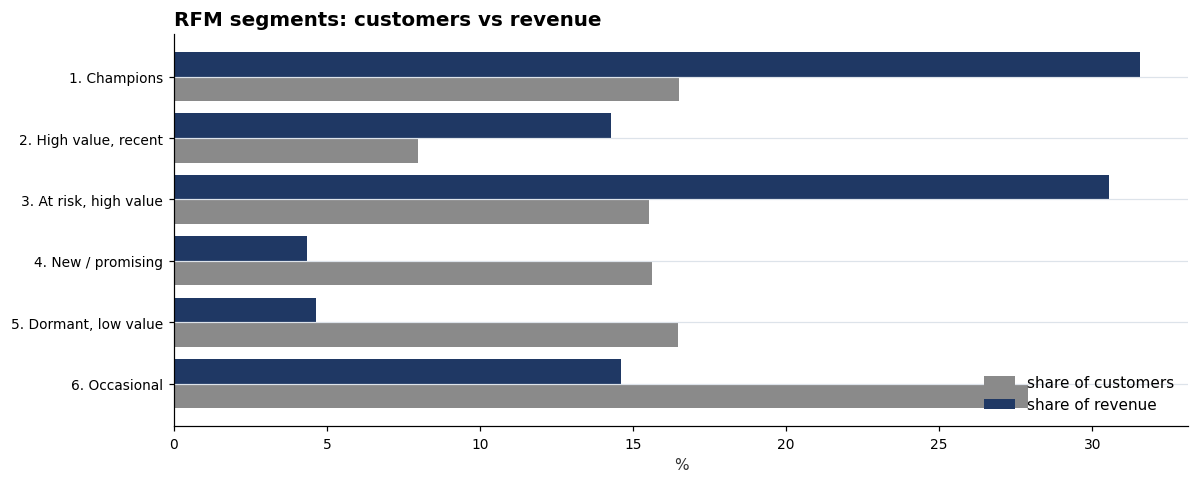

At risk, high value : 14,737 people (15.5%) holding 30.6% of revenue
High-value customers who had at least one late delivery: 2,868


In [5]:
segments = q(f"""
    select
        rfm_segment,
        count(*)                                  as customers,
        round(sum(monetary), 0)                   as revenue,
        round(avg(monetary), 0)                   as avg_monetary,
        round(avg(frequency), 3)                  as avg_frequency,
        round(avg(recency_days), 0)               as avg_recency_days,
        round(avg(if(frequency > 1, 1, 0)), 4)    as repeat_rate,
        round(avg(avg_review_score), 2)           as avg_review,
        countif(is_high_value_with_late_delivery) as high_value_late
    from {marts('agg_customer_rfm')}
    group by rfm_segment
    order by rfm_segment
""")
segments["share_of_customers"] = (segments.customers / segments.customers.sum()).round(4)
segments["share_of_revenue"] = (segments.revenue / segments.revenue.sum()).round(4)
display(segments)

fig, ax = plt.subplots(figsize=(11, 4.5))
y = range(len(segments))
ax.barh([i + 0.2 for i in y], segments.share_of_customers * 100, height=0.4,
        color="#8a8a8a", label="share of customers")
ax.barh([i - 0.2 for i in y], segments.share_of_revenue * 100, height=0.4,
        color="#1f3864", label="share of revenue")
ax.set_yticks(list(y), segments.rfm_segment); ax.invert_yaxis()
ax.set_xlabel("%"); ax.legend(loc="lower right")
ax.set_title("RFM segments: customers vs revenue")
plt.tight_layout(); plt.show()

risk = segments[segments.rfm_segment.str.startswith("3.")].iloc[0]
print(f"At risk, high value : {risk.customers:,.0f} people ({risk.share_of_customers:.1%}) "
      f"holding {risk.share_of_revenue:.1%} of revenue")
print(f"High-value customers who had at least one late delivery: {segments.high_value_late.sum():,.0f}")

## 2. WHY do so few come back?

### 2a. Retention curve

**Definition.** A cohort is everyone whose first kept order fell in the same month.
Retention in month *n* is the share of that cohort with at least one kept order *n*
months later. Month 0 is 100% by construction (a dbt test enforces it). Cohorts are
weighted by size; only cohorts inside the usable coverage window are used.


,months_since_first,cohort_people,active_customers,retention_rate
0,0,94990,94990,1.00000
1,1,94990,429,0.00452
2,2,88781,277,0.00312
3,3,82765,198,0.00239
4,4,76845,182,0.00237
5,5,70259,142,0.00202
6,6,63561,130,0.00205
7,7,56630,104,0.00184
8,8,50273,90,0.00179
9,9,43322,62,0.00143


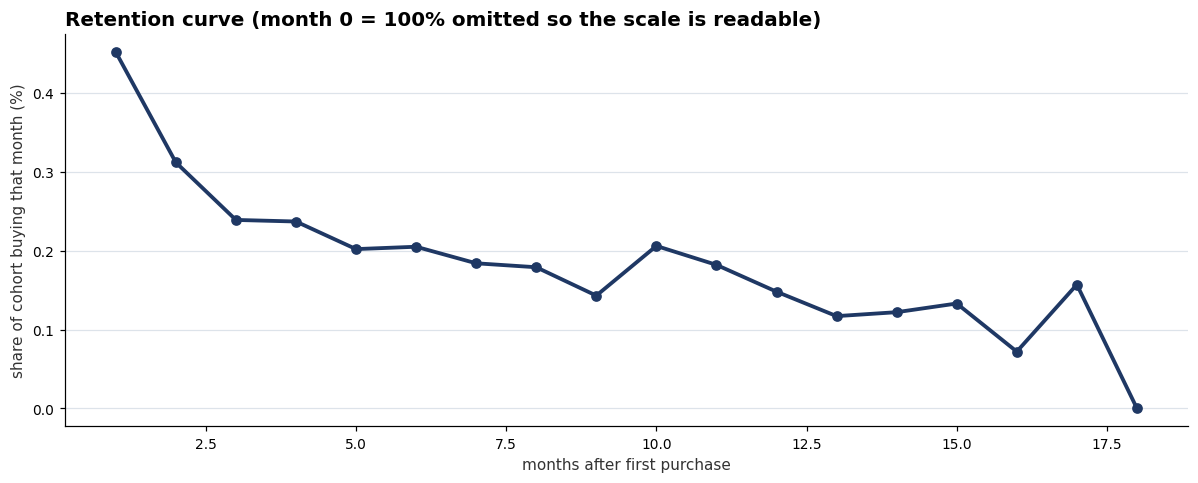

In [6]:
curve = q(f"""
    select
        months_since_first,
        sum(cohort_size)                                      as cohort_people,
        sum(active_customers)                                 as active_customers,
        round(safe_divide(sum(active_customers), sum(cohort_size)), 5) as retention_rate
    from {marts('agg_customer_cohort')}
    where is_in_analysis_window
      and months_since_first between 0 and 18
    group by months_since_first
    order by months_since_first
""")
display(curve.head(13))

later = curve[curve.months_since_first > 0]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(later.months_since_first, later.retention_rate * 100,
        color="#1f3864", marker="o", linewidth=2.5)
ax.set_xlabel("months after first purchase")
ax.set_ylabel("share of cohort buying that month (%)")
ax.set_title("Retention curve (month 0 = 100% omitted so the scale is readable)")
plt.tight_layout(); plt.show()


### 2b. Cohort heatmap

Is retention getting better or worse for newer cohorts? Cohorts under 500 people are
dropped: at that size a single returning customer moves the rate visibly.


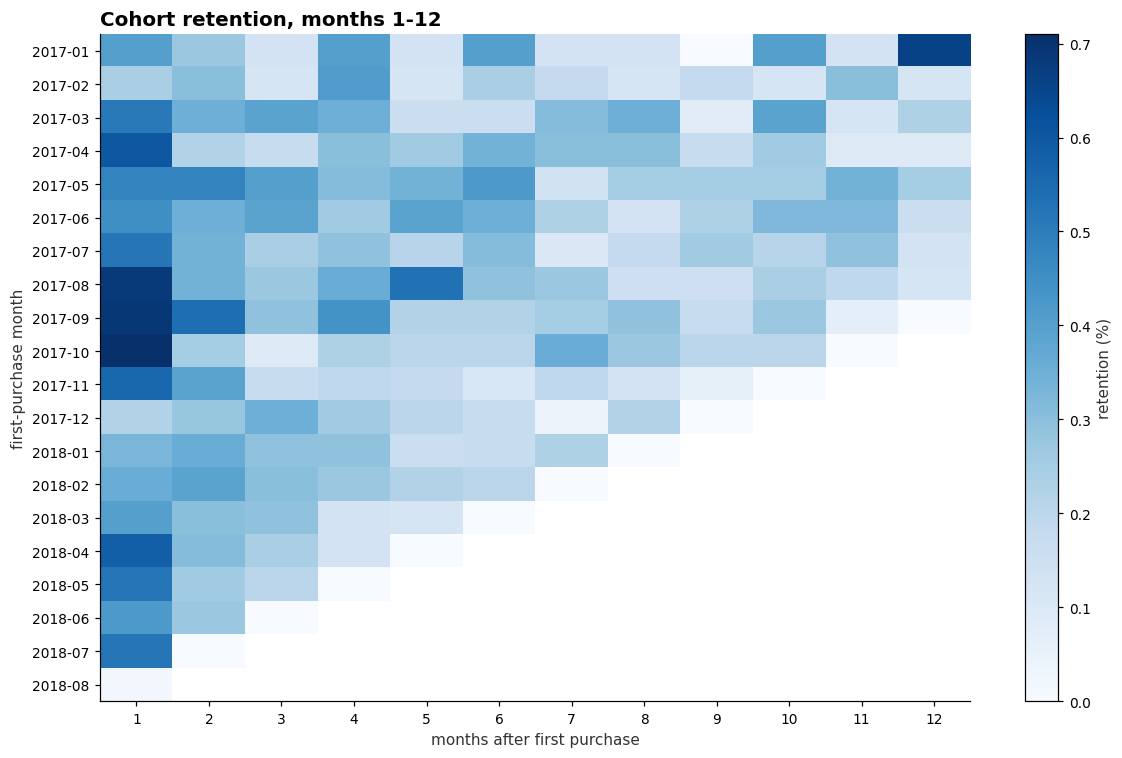

Month-1 retention, best cohort  : 2017-10  0.71%
Month-1 retention, worst cohort : 2018-08  0.02%


In [7]:
cohorts = q(f"""
    select cohort_year_month, months_since_first, retention_rate, cohort_size
    from {marts('agg_customer_cohort')}
    where is_in_analysis_window
      and cohort_size >= 500
      and months_since_first between 1 and 12
""")
grid = cohorts.pivot(index="cohort_year_month", columns="months_since_first",
                     values="retention_rate").sort_index()

fig, ax = plt.subplots(figsize=(11, 7))
im = ax.imshow(grid.values * 100, aspect="auto", cmap="Blues")
ax.set_xticks(range(len(grid.columns)), grid.columns)
ax.set_yticks(range(len(grid.index)), grid.index)
ax.set_xlabel("months after first purchase"); ax.set_ylabel("first-purchase month")
ax.grid(False)
fig.colorbar(im, ax=ax, label="retention (%)")
ax.set_title("Cohort retention, months 1-12")
plt.tight_layout(); plt.show()

month_1 = grid[1].dropna()
print(f"Month-1 retention, best cohort  : {month_1.idxmax()}  {month_1.max():.2%}")
print(f"Month-1 retention, worst cohort : {month_1.idxmin()}  {month_1.min():.2%}")


### 2c. When the second purchase happens

For the minority who do return, how long do they take? This sets how soon a win-back
message should go out.


Customers with a second order : 2,888
Same day                      : 30.1%
Within 30 days                : 50.9%
Median days to second order   : 28


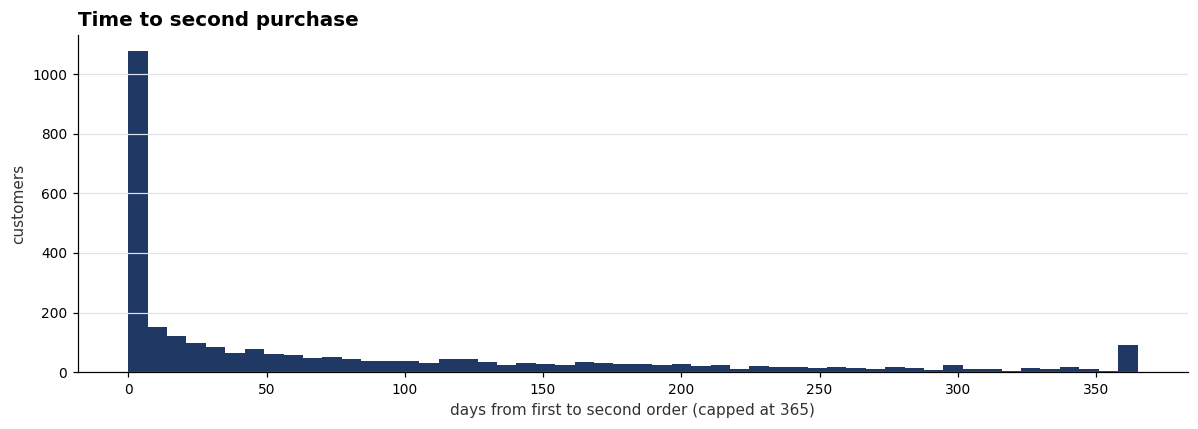

In [8]:
second = q(f"""
    with ranked as (
        select
            customer_key,
            order_purchase_date,
            row_number() over (partition by customer_key
                               order by order_purchased_at, order_id) as n
        from {marts('fct_orders')}
        where not is_excluded_from_kpis
    )
    select date_diff(s.order_purchase_date, f.order_purchase_date, day) as days_to_second
    from ranked f
    join ranked s on f.customer_key = s.customer_key and f.n = 1 and s.n = 2
""")
d = second.days_to_second
print(f"Customers with a second order : {len(d):,}")
print(f"Same day                      : {(d == 0).mean():.1%}")
print(f"Within 30 days                : {(d <= 30).mean():.1%}")
print(f"Median days to second order   : {d.median():.0f}")

fig, ax = plt.subplots(figsize=(11, 4))
ax.hist(d.clip(upper=365), bins=52, color="#1f3864")
ax.set_xlabel("days from first to second order (capped at 365)")
ax.set_ylabel("customers")
ax.set_title("Time to second purchase")
plt.tight_layout(); plt.show()


### 2d. Does a bad first delivery stop people coming back?

The link to the delivery work (business case A): if a late first order lowers the
chance of a second, part of the retention problem is a logistics problem.


In [9]:
first_experience = q(f"""
    with first_order as (
        select
            customer_key, is_late, review_score
        from {marts('fct_orders')}
        where not is_excluded_from_kpis and is_delivered
        qualify row_number() over (partition by customer_key
                                   order by order_purchased_at, order_id) = 1
    )
    select
        case when f.is_late then 'first order late' else 'first order on time' end as first_delivery,
        count(*)                                        as customers,
        round(avg(if(c.is_repeat_customer, 1, 0)), 4)   as repeat_rate,
        round(avg(f.review_score), 2)                   as first_review,
        round(avg(c.lifetime_revenue), 0)               as avg_clv
    from first_order f
    join {marts('agg_customer_clv')} c using (customer_key)
    group by first_delivery
    order by first_delivery desc
""")
display(first_experience)


,first_delivery,customers,repeat_rate,first_review,avg_clv
0,first order on time,87003,0.0312,4.29,141.0
1,first order late,6355,0.0264,2.27,155.0


### 2e. Spend over time: is growth coming from new or returning customers?

**Definition.** From `agg_monthly_sales`: a person's first kept order is **new**, every
later order is **returning** (person grain). Revenue is item price, freight excluded.
Only months inside the usable coverage window are shown.

,year_month,revenue,order_count,new_customers,returning_customers,new_customer_revenue,returning_customer_revenue,returning_revenue_share,avg_order_value,instalment_order_share,instalment_revenue_share,avg_installments
18,2018-04,993592.98,6919,6698,216,965242.93,28350.05,0.0285,143.60,0.4954,0.6463,2.746
19,2018-05,992871.75,6833,6586,239,959431.45,33440.30,0.0337,145.31,0.5115,0.6446,2.889
20,2018-06,863265.53,6145,5920,219,834190.06,29075.47,0.0337,140.48,0.5076,0.6510,2.879
21,2018-07,878044.27,6233,6016,214,851003.77,27040.50,0.0308,140.87,0.4872,0.6244,2.762
22,2018-08,848860.10,6421,6209,205,822350.04,26510.06,0.0312,132.20,0.4977,0.6505,2.789
23,2018-09,145.00,1,0,1,0.00,145.00,1.0000,145.00,0.0000,0.0000,1.000


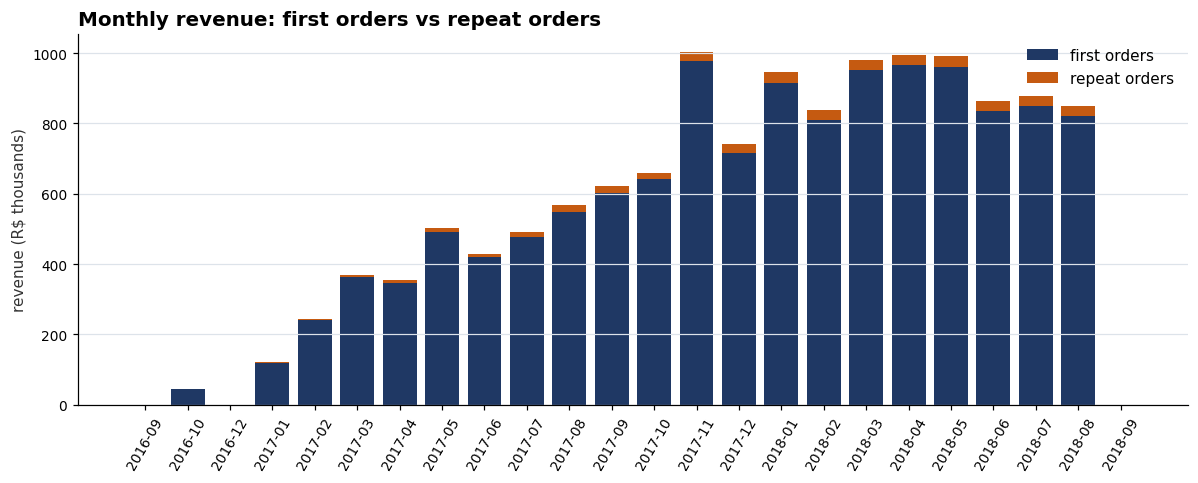

Repeat orders across the window : 2.93% of revenue
Peak month for repeat share     : 2017-12 (3.54%), months with 500+ orders only
year_month  order_count
   2016-09            2
   2016-10          293
   2016-12            1
   2018-09            1


In [10]:
monthly = q(f"""
    select year_month, revenue, order_count, new_customers, returning_customers,
           new_customer_revenue, returning_customer_revenue, returning_revenue_share,
           avg_order_value, instalment_order_share, instalment_revenue_share, avg_installments
    from {marts('agg_monthly_sales')}
    where is_in_analysis_window
    order by year_month
""")
display(monthly.tail(6))

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(monthly.year_month, monthly.new_customer_revenue / 1e3, color="#1f3864", label="first orders")
ax.bar(monthly.year_month, monthly.returning_customer_revenue / 1e3,
       bottom=monthly.new_customer_revenue / 1e3, color="#c55a11", label="repeat orders")
ax.set_ylabel("revenue (R$ thousands)"); ax.legend()
ax.tick_params(axis="x", rotation=60)
ax.set_title("Monthly revenue: first orders vs repeat orders")
plt.tight_layout(); plt.show()

share = monthly.returning_customer_revenue.sum() / monthly.revenue.sum()
print(f"Repeat orders across the window : {share:.2%} of revenue")
# Edge months of the export hold a handful of orders; a "100% repeat" month there
# is noise, so the peak is taken over months with a meaningful order volume only.
solid = monthly[monthly.order_count >= 500]
peak = solid.loc[solid.returning_revenue_share.idxmax()]
print(f"Peak month for repeat share     : {peak.year_month} ({peak.returning_revenue_share:.2%}), "
      f"months with 500+ orders only")
print(monthly.loc[monthly.order_count < 500, ["year_month", "order_count"]].to_string(index=False))

## 3. Do instalments increase basket size?

**Definition.** Average order value (AOV) = order revenue / orders, at order grain from
`agg_installment_basket`. Payments are already collapsed to one row per order in
`fct_orders` (primary payment type, maximum instalment count), so revenue cannot fan out
across multiple payment records.

### 3a. By instalment band (credit card)


,installment_band,orders,revenue,items_per_order,avg_order_value,share_of_card_orders
0,1. Single payment,23725.0,1959744.58,1.100034,82.60,0.3201
1,2. 2-3 instalments,22408.0,2552404.94,1.120707,113.91,0.3023
2,3. 4-6 instalments,15977.0,2512771.26,1.151855,157.27,0.2156
3,4. 7+ instalments,12006.0,3622423.38,1.228004,301.72,0.1620


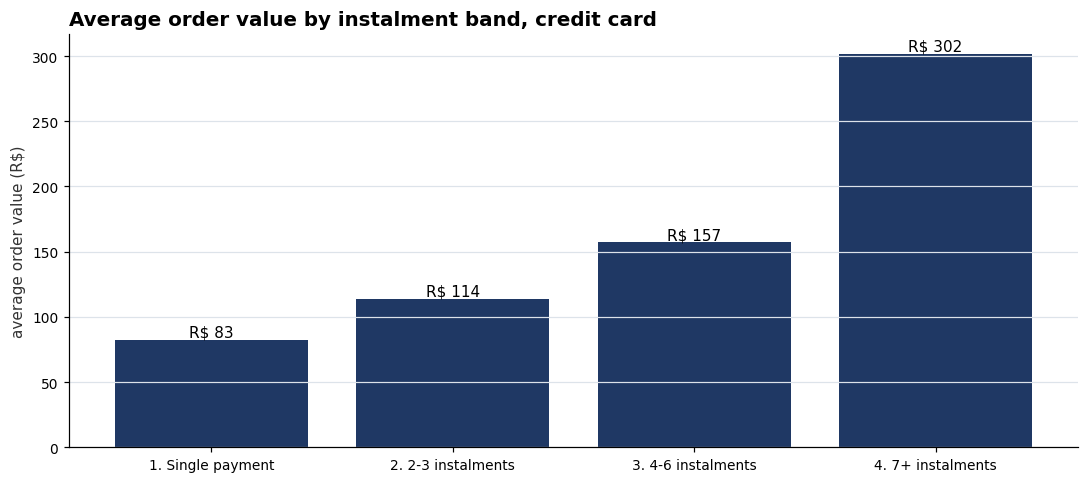

AOV, 7+ instalments vs single payment : 3.7x
Items per order, 7+ vs single         : 1.23 vs 1.10


In [11]:
basket = q(f"""
    select payment_type, installments, installment_band, order_count, customers,
           revenue, avg_order_value, median_order_value, avg_items_per_order,
           late_rate, avg_review_score, is_reportable
    from {marts('agg_installment_basket')}
""")
card = basket[basket.payment_type == "credit_card"]

bands = card.groupby("installment_band").apply(
    lambda g: pd.Series({
        "orders": g.order_count.sum(),
        "revenue": g.revenue.sum(),
        "items_per_order": (g.avg_items_per_order * g.order_count).sum() / g.order_count.sum(),
    }), include_groups=False).reset_index()
bands["avg_order_value"] = (bands.revenue / bands.orders).round(2)
bands["share_of_card_orders"] = (bands.orders / bands.orders.sum()).round(4)
display(bands)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(bands.installment_band, bands.avg_order_value, color="#1f3864")
for x, v in zip(bands.installment_band, bands.avg_order_value):
    ax.text(x, v, f"R$ {v:,.0f}", ha="center", va="bottom")
ax.set_ylabel("average order value (R$)")
ax.set_title("Average order value by instalment band, credit card")
plt.tight_layout(); plt.show()

single = bands.set_index("installment_band").loc["1. Single payment"]
long_ = bands.set_index("installment_band").loc["4. 7+ instalments"]
print(f"AOV, 7+ instalments vs single payment : {long_.avg_order_value / single.avg_order_value:.1f}x")
print(f"Items per order, 7+ vs single         : {long_.items_per_order:.2f} vs {single.items_per_order:.2f}")


### 3b. Every instalment count

Volume and value together. Counts with fewer than 30 orders are hidden
(`min_orders_for_reporting`).


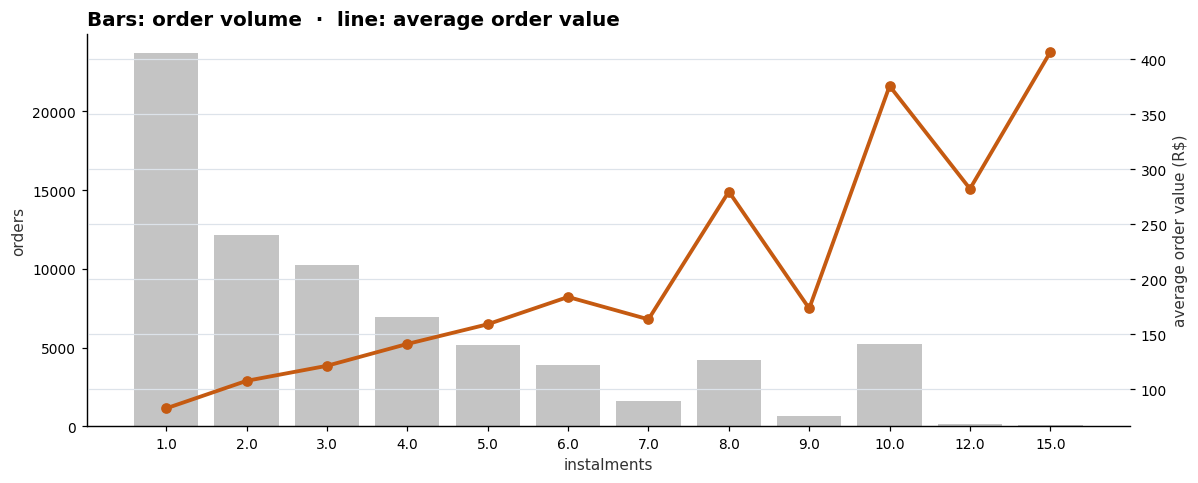

,installments,order_count,avg_order_value,median_order_value,avg_items_per_order,late_rate,avg_review_score
24,1.0,23723,82.60,55.00,1.100,0.0597,4.185
23,2.0,12139,107.64,89.99,1.112,0.0659,4.135
22,3.0,10269,121.32,89.99,1.131,0.0711,4.083
21,4.0,6969,141.20,99.00,1.131,0.0698,4.079
19,5.0,5151,159.09,107.96,1.156,0.0702,4.087
17,6.0,3857,183.94,119.80,1.184,0.0680,4.101
16,7.0,1604,163.57,109.99,1.132,0.0707,4.065
18,8.0,4208,279.79,189.00,1.187,0.0768,4.044
15,9.0,627,173.46,89.90,1.142,0.0878,4.136
20,10.0,5231,375.85,209.99,1.298,0.0726,3.996


In [12]:
detail = card[card.is_reportable].sort_values("installments")
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(detail.installments.astype(str), detail.order_count, color="#8a8a8a", alpha=0.5)
ax1.set_ylabel("orders"); ax1.set_xlabel("instalments"); ax1.grid(False)
ax2 = ax1.twinx()
ax2.plot(detail.installments.astype(str), detail.avg_order_value,
         color="#c55a11", marker="o", linewidth=2.5)
ax2.set_ylabel("average order value (R$)")
ax1.set_title("Bars: order volume  ·  line: average order value")
plt.tight_layout(); plt.show()
display(detail[["installments", "order_count", "avg_order_value", "median_order_value",
                "avg_items_per_order", "late_rate", "avg_review_score"]])


### 3c. By payment type


In [13]:
by_type = basket.groupby("payment_type", as_index=False).agg(
    orders=("order_count", "sum"), revenue=("revenue", "sum"))
by_type["avg_order_value"] = (by_type.revenue / by_type.orders).round(2)
by_type["share_of_orders"] = (by_type.orders / by_type.orders.sum()).round(4)
display(by_type.sort_values("orders", ascending=False))


,payment_type,orders,revenue,avg_order_value,share_of_orders
1,credit_card,74116,10647344.16,143.66,0.7547
0,boleto,19539,2377567.71,121.68,0.1990
4,voucher,3037,288243.18,94.91,0.0309
2,debit_card,1514,181110.72,119.62,0.0154
3,no_payment_record,1,134.97,134.97,0.0000


### 3d. Is instalment usage changing over time?

If the instalment share were rising while AOV rose with it, that would be consistent with
instalments enabling bigger baskets; if AOV is flat while the share moves, the basket
effect in 3a is more likely price-driven selection.

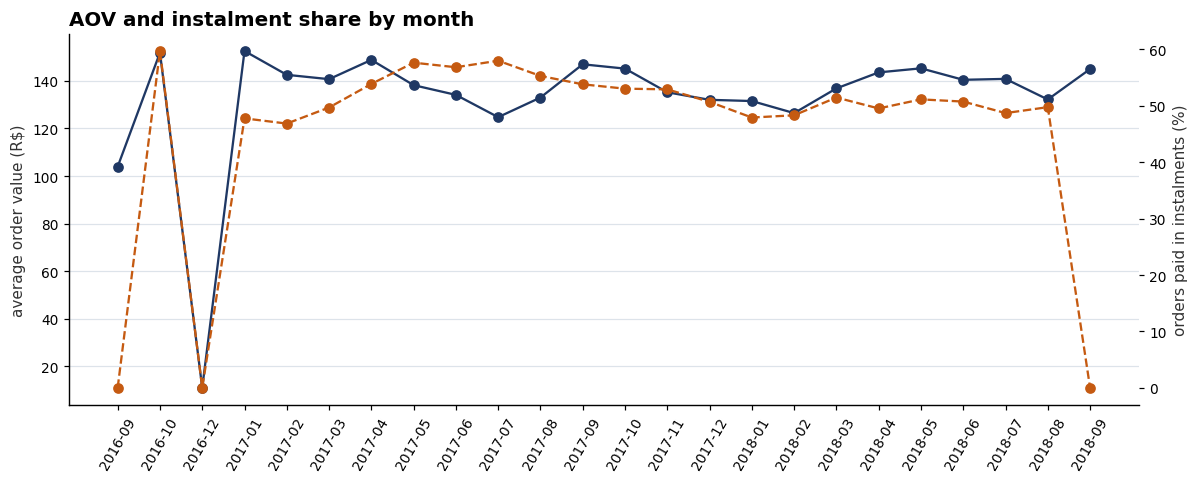

Correlation, monthly AOV vs instalment share: 0.62  (month-level, association only)


In [14]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.year_month, monthly.avg_order_value, color="#1f3864", marker="o", label="AOV (R$)")
ax.set_ylabel("average order value (R$)")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(monthly.year_month, monthly.instalment_order_share * 100, color="#c55a11",
         marker="o", linestyle="--", label="orders in instalments (%)")
ax2.set_ylabel("orders paid in instalments (%)")
ax.tick_params(axis="x", rotation=60)
ax.set_title("AOV and instalment share by month")
plt.tight_layout(); plt.show()

print(f"Correlation, monthly AOV vs instalment share: "
      f"{monthly.avg_order_value.corr(monthly.instalment_order_share):.2f}  (month-level, association only)")

## 4. B + D: does the first payment predict the customer?

Customers grouped by how they paid for their **first** order. Using the first order
(not "ever used instalments") keeps cause before effect: someone who returns has more
chances to use instalments, so "ever used" would inflate the link.

### 4a. Raw comparison (credit-card first orders)


,first_installment_band,customers,repeat_rate,avg_first_order,avg_clv,avg_repeat_revenue
0,1. Single payment,23043,0.0253,83.0,86.0,3.32
1,2. 2-3 instalments,21743,0.0288,114.0,118.0,3.37
2,3. 4-6 instalments,15401,0.0322,159.0,163.0,4.32
3,4. 7+ instalments,11490,0.0412,306.0,313.0,7.40


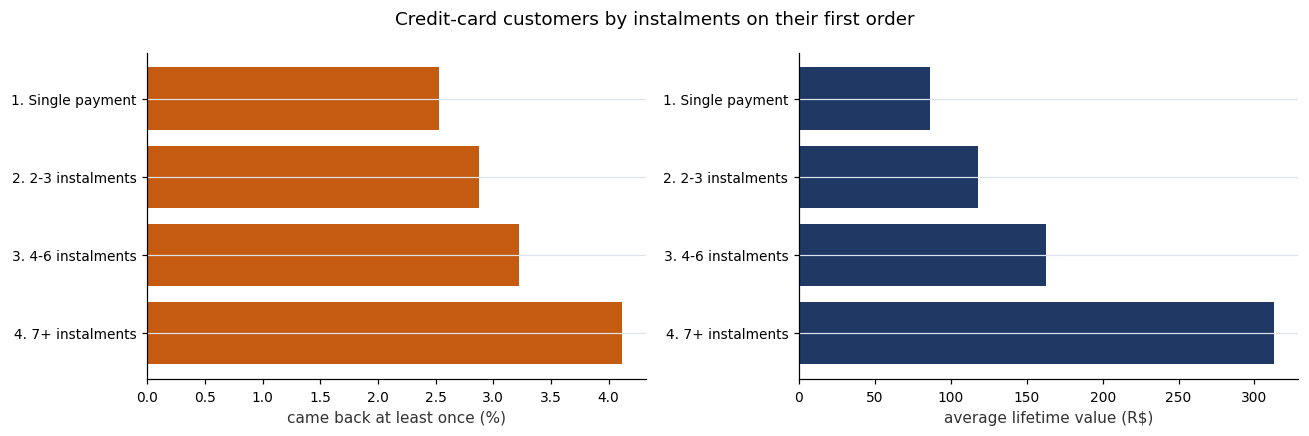

In [15]:
by_first = q(f"""
    select
        first_installment_band,
        count(*)                                     as customers,
        round(avg(if(is_repeat_customer, 1, 0)), 4)  as repeat_rate,
        round(avg(first_order_revenue), 0)           as avg_first_order,
        round(avg(lifetime_revenue), 0)              as avg_clv,
        round(avg(repeat_revenue), 2)                as avg_repeat_revenue
    from {marts('agg_customer_clv')}
    where first_payment_type = 'credit_card'
    group by first_installment_band
    order by first_installment_band
""")
display(by_first)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].barh(by_first.first_installment_band, by_first.repeat_rate * 100, color="#c55a11")
axes[0].set_xlabel("came back at least once (%)"); axes[0].invert_yaxis()
axes[1].barh(by_first.first_installment_band, by_first.avg_clv, color="#1f3864")
axes[1].set_xlabel("average lifetime value (R$)"); axes[1].invert_yaxis()
fig.suptitle("Credit-card customers by instalments on their first order")
plt.tight_layout(); plt.show()


### 4b. Controlling for price

The obvious objection: people who use long instalments are buying expensive things, and
maybe buyers of expensive things simply come back more. So compare repeat rates
**within the same first-order price band**. If the gap survives inside each band, price
alone does not explain it.


In [16]:
controlled = q(f"""
    select
        case
            when first_order_revenue < 50  then '1. < R$50'
            when first_order_revenue < 100 then '2. R$50-100'
            when first_order_revenue < 200 then '3. R$100-200'
            when first_order_revenue < 500 then '4. R$200-500'
            else '5. R$500+'
        end                                          as first_order_price,
        first_order_installments > 1                 as used_instalments,
        count(*)                                     as customers,
        round(avg(if(is_repeat_customer, 1, 0)), 4)  as repeat_rate
    from {marts('agg_customer_clv')}
    where first_payment_type = 'credit_card'
      and first_order_revenue is not null
    group by first_order_price, used_instalments
    order by first_order_price, used_instalments
""")
wide = controlled.pivot(index="first_order_price", columns="used_instalments",
                        values=["repeat_rate", "customers"])
wide.columns = [f"{m}_{'instalments' if k else 'single'}" for m, k in wide.columns]
wide["gap_pp"] = ((wide.repeat_rate_instalments - wide.repeat_rate_single) * 100).round(2)
display(wide)
print("Bands where instalment users repeat MORE than single-payment users:",
      int((wide.gap_pp > 0).sum()), "of", len(wide))


,repeat_rate_single,repeat_rate_instalments,customers_single,customers_instalments,gap_pp
first_order_price,,,,,
1. < R$50,0.0247,0.0430,10788.0,9062.0,1.83
2. R$50-100,0.0261,0.0363,7129.0,13315.0,1.02
3. R$100-200,0.0238,0.0293,3824.0,15713.0,0.55
4. R$200-500,0.0341,0.0270,1085.0,7861.0,-0.71
5. R$500+,0.0092,0.0179,217.0,2679.0,0.87


Bands where instalment users repeat MORE than single-payment users: 4 of 5


## 5. Reconciliation

The dbt tests `assert_cohort_reconciles` and `assert_customer_value_reconciles` enforce
these on every build. Repeating them here shows this notebook's figures are the same
ones the pipeline tested.


In [17]:
recon = q(f"""
    select
        (select count(*) from {marts('agg_customer_rfm')})                   as rfm_people,
        (select count(*) from {marts('agg_customer_clv')})                   as clv_people,
        (select sum(cohort_size) from {marts('agg_customer_cohort')}
          where months_since_first = 0)                                      as cohort_people,
        (select round(sum(lifetime_revenue), 2) from {marts('agg_customer_clv')}) as clv_revenue,
        (select round(sum(revenue), 2) from {marts('agg_installment_basket')})    as basket_revenue,
        (select round(sum(revenue), 2) from {marts('agg_customer_cohort')})       as cohort_revenue,
        (select round(sum(order_revenue), 2) from {marts('fct_orders')}
          where not is_excluded_from_kpis)                                   as fact_revenue
""").iloc[0]
display(recon.to_frame("value"))

assert recon.rfm_people == recon.clv_people == recon.cohort_people, "population mismatch"
assert recon.clv_revenue == recon.basket_revenue == recon.cohort_revenue == recon.fact_revenue, \
    "revenue does not reconcile"
print("Reconciled: same people, same revenue, to the cent, across all three new models.")


,value
rfm_people,94990.00
clv_people,94990.00
cohort_people,94990.00
clv_revenue,13494400.74
basket_revenue,13494400.74
cohort_revenue,13494400.74
fact_revenue,13494400.74


Reconciled: same people, same revenue, to the cent, across all three new models.


## Insight cards

Each card has all five parts (an observation without an action is not a finding). Every
figure is quoted from the executed cells above; impact estimates show their arithmetic
and assumptions so they can be challenged. Revenue = item price, freight excluded.

### Insight 1  -  WHO is valuable (B)
- **Observation:** The top 10% of customers (lifetime spend R\$ 282+) hold **41.1%** of
  revenue, and the top 20% hold 56.7% (1a). They are not loyal regulars: they average
  1.11 orders, against 1.03 for everyone else. What sets them apart is a **R\$ 559 first
  order** (vs R\$ 91), and 74% of them paid that first order in instalments (vs 49%) (1b).
  In RFM terms, *At risk, high value* is 15.5% of people but **30.6% of revenue**, almost
  as much as *Champions* (31.6%), and their last order was on average 444 days ago (1c).
- **Interpretation:** Value at Olist comes from one large basket, not repeat visits. The
  most valuable people are identifiable at their first purchase (high ticket, instalments),
  and a large share of that value is already lapsing.
- **Decision:** Treat a first order above R\$ 282 as a "high-value acquisition" trigger for
  a dedicated post-purchase journey. Run a personal win-back offer for the 14,737
  *At risk, high value* customers first, ahead of any broad campaign.
- **Expected impact:** Winning back 5% of *At risk, high value* = 737 people × one order at
  their average R\$ 265 per order (R\$ 280 ÷ 1.055 orders) ≈ **R\$ 195k**, about 1.4% of
  revenue, from a list of under 15k people.
- **Caveat:** CLV is realised spend over a 2-year export, not a forecast. Customers
  acquired in 2018 have had less time to spend.

### Insight 2  -  WHY so few come back (B)
- **Observation:** Only **3.04%** of 94,990 people ever buy twice, and repeat orders are
  2.93% of revenue. After month 0, no month brings back more than 0.45% of a cohort
  (month 1), falling to 0.15% by month 12 (2a). For those who do return, 30.1% do so on the
  **same day** and the median gap is **28 days** (2c). A late first delivery cuts the
  first review from 4.29★ to 2.27★ but moves the repeat rate only from 3.12% to 2.64% (2d).
  Even in the best month (2017-12) repeat orders were just 3.54% of revenue (2e).
- **Interpretation:** Growth is almost entirely acquisition. Many "second orders" are a
  same-day top-up, so genuine retention is lower still. Late delivery hurts satisfaction
  badly but explains only a small part of the churn: most customers simply have no
  reason to come back.
- **Decision:** Build a second-purchase programme timed to the first 30 days (where half
  of all second orders happen): post-delivery recommendation plus a time-limited voucher.
  Keep fixing late delivery for its review damage, but do not sell it as the retention fix.
- **Expected impact:** Each +1 percentage point of repeat rate = ~950 extra repeat
  customers × R\$ 137 average order ≈ **R\$ 130k** (≈1% of revenue) per point. Closing the
  late-vs-on-time gap entirely would add only ~30 repeat customers (6,355 × 0.48 pp), which
  is why delivery is not the main lever.
- **Caveat:** Olist is a marketplace; a customer may return to a seller's own channel,
  which this data cannot see.

### Insight 3  -  Instalments and basket size (D)
- **Observation:** Credit-card orders on **7+ instalments average R\$ 302**, against
  R\$ 83 for a single payment: **3.7×** (3a). Items per order barely move (1.23 vs 1.10),
  so the gap is the price of the item, not a fuller basket. 68% of card orders use
  instalments, and month by month the instalment share and AOV move together
  (correlation 0.62, 3d). Card is 75% of orders; boleto (20%) has no instalment option
  and averages R\$ 122 (3c).
- **Interpretation:** Instalments go with buying **more expensive items**, not more items.
  Most of that is customers choosing instalments because the item is expensive, so the
  3.7× is an upper bound on any effect, not an estimate of it.
- **Decision:** Do not roll out longer instalments on the strength of this chart. Run a
  randomised checkout test: show a longer instalment plan to a random half of card
  customers in mid- and high-price categories and compare order value and conversion.
- **Expected impact:** Single-payment card orders are R\$ 1.96M of revenue. If the test
  showed even a 10% AOV lift on them, that is **≈ R\$ 196k**; if it shows nothing, the
  company avoids extending credit for no return.
- **Caveat:** Association, not causation. Expensive items drive instalment choice at
  least as much as instalments drive spend. A randomised instalment offer is the only
  way to measure the causal effect.

### Insight 4  -  First payment and retention (B + D)
- **Observation:** Card customers whose **first** order used 7+ instalments came back at
  **4.12%**, against 2.53% for a single payment, and are worth R\$ 313 vs R\$ 86 (4).
  Comparing within the same first-order price band, instalment users repeat more in
  **4 of 5 bands**, by up to 1.8 pp under R\$ 50 (4b). The R\$ 200-500 band is the exception
  (2.70% vs 3.41%).
- **Interpretation:** The link is not only price: even on cheap first orders, people who
  chose instalments come back more often. Instalments may mark a customer who plans
  ahead and trusts the platform, or they may lower the cost of a second purchase. The data
  cannot separate the two.
- **Decision:** Fold a retention arm into the Insight 3 experiment: track 90-day repeat
  rate for customers offered instalments on their first order, alongside AOV. Until then,
  use "first order in instalments" as a targeting signal for the 30-day second-purchase
  programme in Insight 2.
- **Expected impact:** Modest in money and worth stating plainly: lifting the 23,043
  single-payment-first card customers to the 2-3 instalment band's 2.88% repeat rate is
  ~81 extra repeat customers × R\$ 137 ≈ **R\$ 11k**. The value is in the targeting signal and
  in the experiment's answer, not in a direct revenue gain.
- **Caveat:** Price is controlled in 4b; income, product category and seller are not.